# Лабораторная работа 3. Стационарность, ACF и PACF

Цель — проверить, как обычные и сезонные разности меняют свойства ряда. Моделируем 300 месячных наблюдений как сумму дрейфа, случайного блуждания, устойчивого годового профиля и шума измерения. Дисперсию инноваций задаём постоянной.

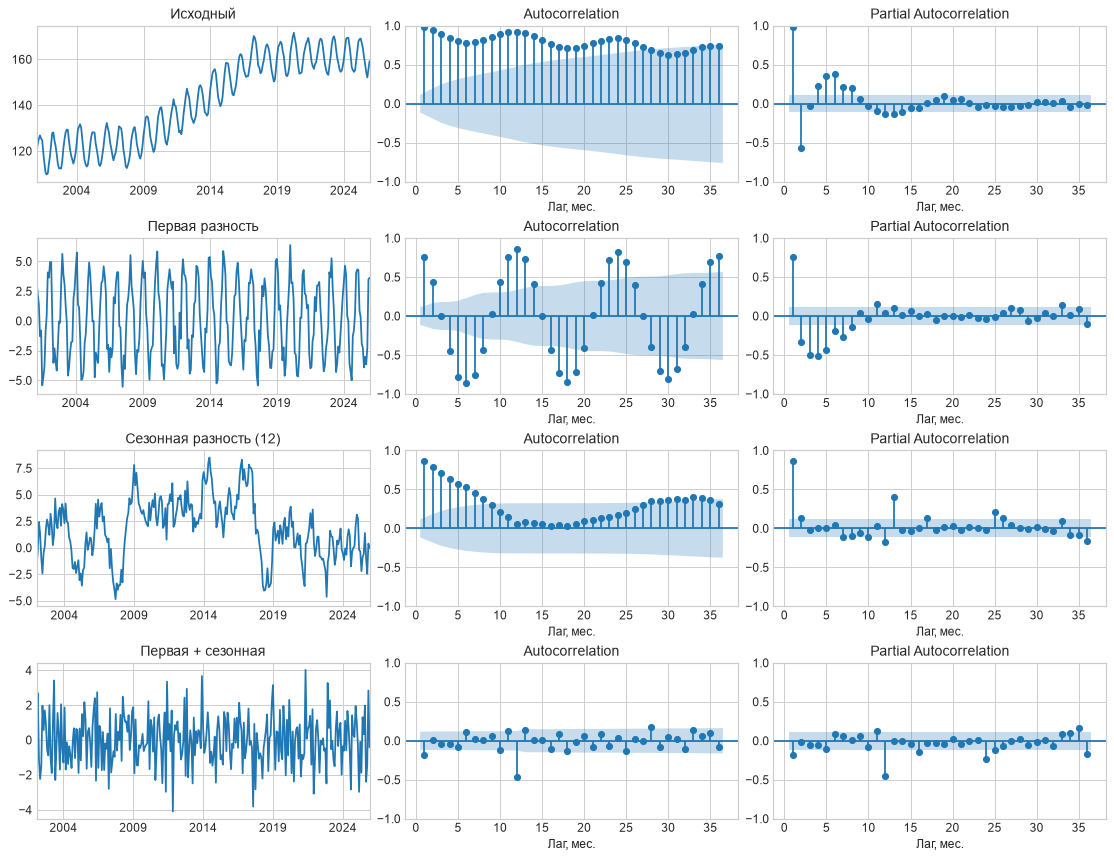

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch.unitroot import PhillipsPerron, DFGLS
from pmdarima.arima import ndiffs, nsdiffs
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 85
rng = np.random.default_rng(303)
t = np.arange(300)
y = pd.Series(120 + 0.18 * t + np.cumsum(rng.normal(0, 0.9, len(t)))
              + 8 * np.sin(2 * np.pi * t / 12) + rng.normal(0, 0.25, len(t)),
              index=pd.date_range("2001-01-01", periods=len(t), freq="MS"))

variants = {
    "Исходный": y,
    "Первая разность": y.diff().dropna(),
    "Сезонная разность (12)": y.diff(12).dropna(),
    "Первая + сезонная": y.diff().diff(12).dropna(),
}
fig, axes = plt.subplots(len(variants), 3, figsize=(13, 10), layout="constrained")
for row, (name, series) in zip(axes, variants.items()):
    series.plot(ax=row[0], title=name, xlabel="")
    plot_acf(series, ax=row[1], lags=36, zero=False)
    plot_pacf(series, ax=row[2], lags=36, method="ywm", zero=False)
    for axis in row[1:]:
        axis.set_xlabel("Лаг, мес.")
plt.show()

Нулевая гипотеза ADF, PP и DF-GLS — единичный корень. У KPSS нулевая гипотеза — стационарность вокруг постоянного уровня. Порог принятия решения равен 0,05. Сравнение с константой даёт одинаковую спецификацию для всех четырёх рядов. Значения 0,01 и 0,10 у KPSS могут быть границами табличного диапазона.

In [2]:
test_results = []
for name, x in variants.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        kpss_p = kpss(x, regression="c", nlags="auto", result_object=False)[1]
    test_results.append({
        "Ряд": name, "ADF": adfuller(x, regression="c", autolag="AIC", result_object=False)[1],
        "PP": PhillipsPerron(x, trend="c").pvalue,
        "KPSS": kpss_p, "DF-GLS": DFGLS(x, trend="c").pvalue,
    })
results = pd.DataFrame(test_results).set_index("Ряд")
display(results.map(lambda p: f"{p:.4g}"))
reject = results.lt(0.05).replace({True: "Отклоняем H₀", False: "Нет оснований отклонить H₀"})
display(reject)

seasonal_d = {test: nsdiffs(y.to_numpy(), m=12, test=test) for test in ("ch", "ocsb")}
recommendations = pd.DataFrame([
    {"Сезонный тест": test, "D": D,
     "d (KPSS)": ndiffs((y.diff(12).dropna() if D else y).to_numpy(), test="kpss")}
    for test, D in seasonal_d.items()
])
display(recommendations)

,ADF,PP,KPSS,DF-GLS
Ряд,,,,
Исходный,0.7881,0.5289,0.01,0.8091
Первая разность,0.0134,2.18e-05,0.1,0.6291
Сезонная разность (12),0.05812,0.0001283,0.1,0.1042
Первая + сезонная,1.214e-10,0,0.1,0.1159


,ADF,PP,KPSS,DF-GLS
Ряд,,,,
Исходный,Нет оснований отклонить H₀,Нет оснований отклонить H₀,Отклоняем H₀,Нет оснований отклонить H₀
Первая разность,Отклоняем H₀,Отклоняем H₀,Нет оснований отклонить H₀,Нет оснований отклонить H₀
Сезонная разность (12),Нет оснований отклонить H₀,Отклоняем H₀,Нет оснований отклонить H₀,Нет оснований отклонить H₀
Первая + сезонная,Отклоняем H₀,Отклоняем H₀,Нет оснований отклонить H₀,Нет оснований отклонить H₀


,Сезонный тест,D,d (KPSS)
0,ch,0,1
1,ocsb,0,1


### Выводы

- Исходный ряд содержит дрейф и стохастический тренд. Медленное затухание исходной ACF согласуется с накоплением случайных изменений уровня. На исходном ряду ADF, PP и DF-GLS не отвергают единичный корень, а KPSS отвергает стационарность уровня.
- Первая разность убирает накопление инноваций, однако на коррелограмме остаются повторяющиеся пики на сезонных лагах. Годовой профиль был задан детерминированно. Тесты на обычный единичный корень сами по себе не проверяют, исчезла ли сезонность.
- Сезонная разность содержит множитель обычной разности, поскольку $1-B^{12}=(1-B)(1+B+\cdots+B^{11})$. В нашем эксперименте она одновременно устраняет годовой профиль и превращает случайное блуждание в сумму последних 12 инноваций. Остаточная ACF на коротких лагах для такой суммы ожидаема.
- Для этого учебного ряда выбираем **сезонную разность 12 без дополнительной первой разности**. После сезонной разности PP отвергает единичный корень, KPSS не отвергает стационарность, а ADF (p = 0,058) и DF-GLS (p = 0,104) дают менее определённую картину. Скользящая сумма 12 инноваций создаёт сильную краткосрочную зависимость, поэтому ориентируемся также на механизм генерации и исчезновение сезонного рисунка. Дополнительная первая разность повышает риск передифференцирования. Детерминированные месячные эффекты с первой разностью — ещё один способ учесть заданный сезонный профиль при моделировании.
- CH и OCSB рекомендуют D = 0, а KPSS рекомендует d = 1. Это согласуется с решением использовать первую разность и отдельно учесть детерминированные месячные эффекты. Устойчивый детерминированный профиль может оставаться даже при автоматическом $D=0$. Логарифмирование здесь не требуется, поскольку рост дисперсии инноваций не задан.